**Autores:** Jesús Moreno Cruz y Corro

# Escalado
Conjunto de datos: iris (incluido en sklearn)
Este conjunto de datos es compacto y perfecto para demostrar técnicas de escalado.

In [1]:
# Importar librerías necesarias
from sklearn.datasets import load_iris
from sklearn.preprocessing import MinMaxScaler, StandardScaler
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
# Cargar el conjunto de datos
iris = load_iris(as_frame=True)
data = iris.data

In [3]:
# Visualizar las estadísticas iniciales
print("Estadísticas iniciales:")
data.describe()

Estadísticas iniciales:


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
count,150.000000,150.000000,150.000000,150.000000
mean,5.843333,3.057333,3.758000,1.199333
std,0.828066,0.435866,1.765298,0.762238
min,4.300000,2.000000,1.000000,0.100000
25%,5.100000,2.800000,1.600000,0.300000
50%,5.800000,3.000000,4.350000,1.300000
75%,6.400000,3.300000,5.100000,1.800000
max,7.900000,4.400000,6.900000,2.500000


In [4]:
# Aplicar MinMaxScaler
minmax_scaler = MinMaxScaler()
data_minmax = pd.DataFrame(minmax_scaler.fit_transform(data), columns=data.columns)

In [5]:
# Aplicar StandardScaler
standard_scaler = StandardScaler()
data_standard = pd.DataFrame(standard_scaler.fit_transform(data), columns=data.columns)

# Ejercicios
Contesta las siguientes preguntas. Para cada pregunta, deberás escribir código que demostrará cómo llegaste al resultado. Crea gráficas en donde veas correcto.

### 1. ¿Qué diferencias encuentras entre las estadísticas originales y las del escalado MinMax?


In [6]:
# Ejercicio 1: estadísticas originales vs. MinMaxScaler lado a lado
pd.concat({
    'original': data.describe().T[['min', 'max', 'mean', 'std']],
    'minmax': data_minmax.describe().T[['min', 'max', 'mean', 'std']],
}, axis=1).round(3)

original                    minmax                   
                       min  max   mean    std    min  max   mean    std
sepal length (cm)      4.3  7.9  5.843  0.828    0.0  1.0  0.429  0.230
sepal width (cm)       2.0  4.4  3.057  0.436    0.0  1.0  0.441  0.182
petal length (cm)      1.0  6.9  3.758  1.765    0.0  1.0  0.467  0.299
petal width (cm)       0.1  2.5  1.199  0.762    0.0  1.0  0.458  0.318

**Respuesta:** MinMaxScaler lleva cada variable al rango [0, 1]. Las estadísticas de posición y dispersión cambian, pero la forma de la distribución no:

- `sepal length (cm)`: media 5.843 → 0.429, desviación 0.828 → 0.230.
- `petal width (cm)`: media 1.199 → 0.458, desviación 0.762 → 0.318.

Las variables originales tienen rangos muy distintos (por ejemplo, `petal length` va de 1.0 a 6.9 y `sepal width` de 2.0 a 4.4); después del escalado todas quedan en la misma escala.

### 2. Crea una gráfica de la distribución de la variable 'sepal length (cm)' antes y después del escalado.

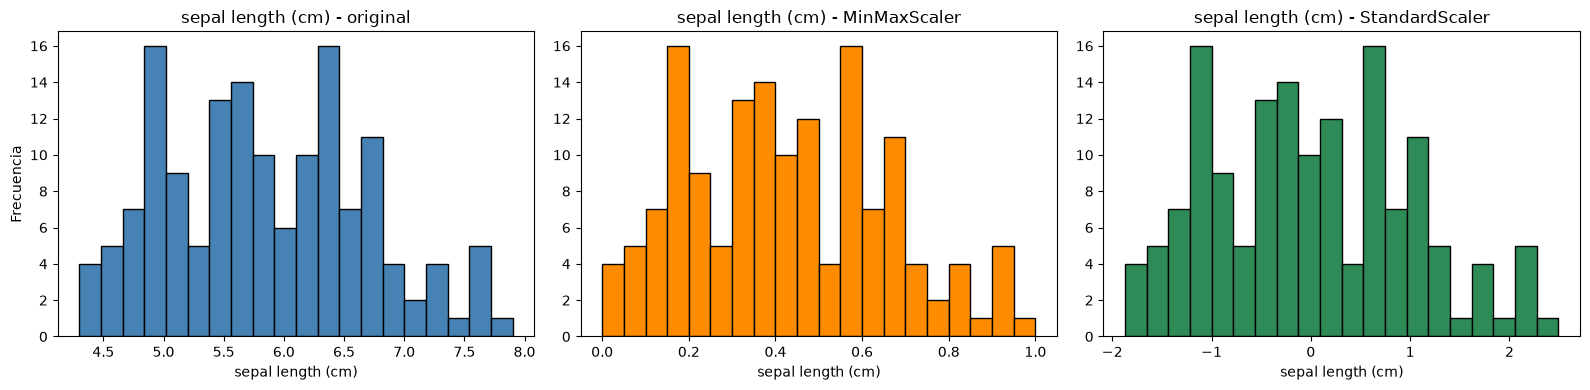

In [7]:
# Ejercicio 2: distribución de 'sepal length (cm)' antes y después del escalado
fig, ejes = plt.subplots(1, 3, figsize=(16, 4))
columna = 'sepal length (cm)'

ejes[0].hist(data[columna], bins=20, color='steelblue', edgecolor='black')
ejes[0].set_title(f'{columna} - original')

ejes[1].hist(data_minmax[columna], bins=20, color='darkorange', edgecolor='black')
ejes[1].set_title(f'{columna} - MinMaxScaler')

ejes[2].hist(data_standard[columna], bins=20, color='seagreen', edgecolor='black')
ejes[2].set_title(f'{columna} - StandardScaler')

for ax in ejes:
    ax.set_xlabel(columna)
ejes[0].set_ylabel('Frecuencia')
plt.tight_layout()
plt.show()

**Respuesta:** en los tres histogramas la forma de la distribución es la misma; solo cambia el eje horizontal. MinMax la lleva a [0, 1] y StandardScaler la centra en 0 con desviación 1.

### 3. Crea una gráfica de dispersión entre 'sepal length (cm)' y 'sepal width (cm)' con los datos escalados por StandardScaler.

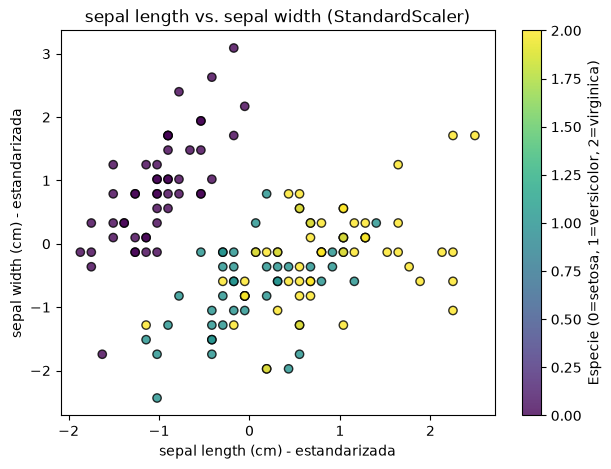

In [8]:
# Ejercicio 3: dispersión de sepal length vs. sepal width con StandardScaler
plt.figure(figsize=(7, 5))
dispersion = plt.scatter(
    data_standard['sepal length (cm)'],
    data_standard['sepal width (cm)'],
    c=iris.target, cmap='viridis', edgecolor='k', alpha=0.8,
)
plt.xlabel('sepal length (cm) - estandarizada')
plt.ylabel('sepal width (cm) - estandarizada')
plt.title('sepal length vs. sepal width (StandardScaler)')
plt.colorbar(dispersion, label='Especie (0=setosa, 1=versicolor, 2=virginica)')
plt.show()

**Respuesta:** con StandardScaler ambas variables quedan centradas en 0, así que el origen de la gráfica representa el promedio de cada una. Las especies se distinguen por color; setosa (0) tiende a tener sépalos más cortos y más anchos, por lo que aparece hacia la derecha y abajo.

### 4. ¿Qué técnica de escalado crees que es más adecuada para este conjunto de datos? ¿Por qué?

                   rango  media   std
sepal length (cm)    3.6   5.84  0.83
sepal width (cm)     2.4   3.06  0.44
petal length (cm)    5.9   3.76  1.77
petal width (cm)     2.4   1.20  0.76


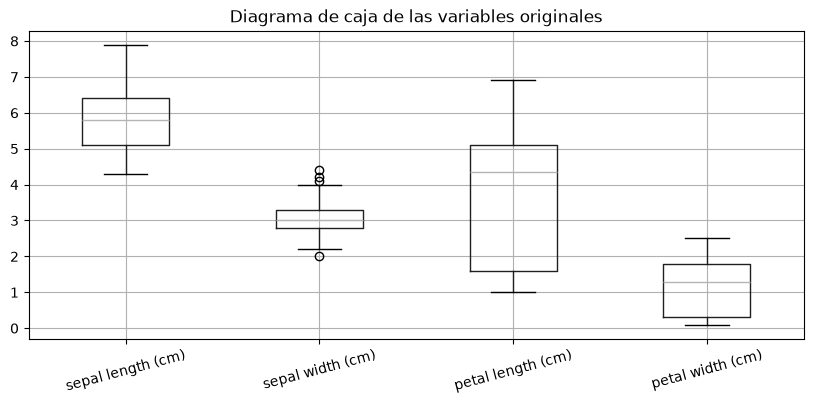

In [9]:
# Ejercicio 4: rango, media y desviación de cada variable, y valores atípicos
resumen_escala = pd.DataFrame({
    'rango': data.max() - data.min(),
    'media': data.mean(),
    'std': data.std(),
}).round(2)
print(resumen_escala)

data.boxplot(figsize=(10, 4), rot=15)
plt.title('Diagrama de caja de las variables originales')
plt.show()

**Respuesta:** recomiendo **StandardScaler**, por estas razones:

- Las variables tienen distribuciones casi simétricas (asimetría entre -0.31 y 0.32), así que la estandarización funciona bien.
- Deja todas las variables con media 0 y desviación 1, lo que favorece a métodos basados en distancia (KNN, SVM, K-means) y a PCA.
- `sepal width (cm)` tiene 4 valores atípicos según el criterio del rango intercuartílico. Son pocos y no muy extremos; si fueran más extremos, convendría `RobustScaler`.

MinMaxScaler sería preferible si se necesita un rango fijo [0, 1], por ejemplo para redes neuronales con activación sigmoide.